In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C

# 07 - Final evaluation
Curated final table `results/FINAL_RESULTS.csv` (baselines recomputed from saved predictions; transformers from the owner-verified Colab summary or raw run files).

In [2]:
fin = pd.read_csv(C.ROOT_DIR / 'results' / 'FINAL_RESULTS.csv', keep_default_na=False)
display(fin.drop(columns=['Source']))

,Model,Family,Accuracy,Precision,Recall,Macro_F1,Weighted_F1,Macro_F1_CI95,Role,Hardware
0,Char TF-IDF + Logistic Regression,CPU baseline (TF-IDF),0.9872,0.9931,0.9290,0.9762,0.9870,"[0.952, 0.990]",highest observed test macro-F1 among the 8 models,CPU (1 core)
1,Char TF-IDF + Linear SVM,CPU baseline (TF-IDF),0.9861,0.9931,0.9226,0.9741,0.9859,"[0.949, 0.988]",validation-selected CPU baseline,CPU (1 core)
2,Word TF-IDF + Logistic Regression,CPU baseline (TF-IDF),0.9690,0.8938,0.9226,0.9446,0.9692,"[0.857, 0.987]",,CPU (1 core)
3,Word TF-IDF + Linear SVM,CPU baseline (TF-IDF),0.9861,0.9931,0.9226,0.9741,0.9859,"[0.948, 0.989]",,CPU (1 core)
4,Word TF-IDF + Naive Bayes,CPU baseline (TF-IDF),0.9369,0.7927,0.8387,0.8885,0.9376,"[0.750, 0.967]",,CPU (1 core)
5,Char TF-IDF + Naive Bayes,CPU baseline (TF-IDF),0.9283,0.7500,0.8516,0.8770,0.9301,"[0.718, 0.967]",,CPU (1 core)
6,mBERT,Transformer,0.9369,0.8750,0.7226,0.8772,0.9344,"[0.754, 0.970]",,NVIDIA Tesla T4
7,XLM-R,Transformer,0.9850,0.9862,0.9226,0.9722,0.9848,"[0.946, 0.987]",best-performing transformer,NVIDIA Tesla T4


## Cross-lingual experiments A/B/C (fixed split; Roman Urdu+Mixed test = 5 independent groups)

,model_id,experiment,n_train,n_test,n_groups,macro_f1,macro_f1_ci_low,macro_f1_ci_high,status
0,char_lr,A: combined -> English,4308.0,782,770,0.963,0.939,0.981,ok
1,char_lr,A: combined -> Roman Urdu+Mixed,4308.0,149,5,1.000,0.500,1.000,descriptive only: 5 independent groups (< 20); CI/point estimates unreliable
2,char_lr,B: English-only -> Roman Urdu+Mixed (zero-shot),3729.0,149,5,0.377,0.009,0.500,descriptive only: 5 independent groups (< 20); CI/point estimates unreliable
3,char_lr,B: Roman Urdu+Mixed-only -> English (zero-shot),556.0,782,770,0.466,0.459,0.473,ok
4,char_lr,C: English-only -> English,3729.0,782,770,0.966,0.944,0.983,ok
5,char_lr,C: Roman Urdu+Mixed-only -> Roman Urdu+Mixed,556.0,149,5,1.000,0.500,1.000,descriptive only: 5 independent groups (< 20); CI/point estimates unreliable
6,char_lr,C-diff: combined minus language-specific on English,NaN,782,770,-0.003,-0.009,0.000,CI excludes 0: False; McNemar exact p=1 (discordant 0/1; p optimistic: clust...
7,char_lr,C-diff: combined minus language-specific on Roman Urdu+Mixed,NaN,149,5,0.000,0.000,0.000,CI excludes 0: False; McNemar exact p=1 (discordant 0/0; p optimistic: clust...
8,word_lr,A: combined -> English,4308.0,782,770,0.962,0.940,0.981,ok
9,word_lr,A: combined -> Roman Urdu+Mixed,4308.0,149,5,0.885,0.429,1.000,descriptive only: 5 independent groups (< 20); CI/point estimates unreliable


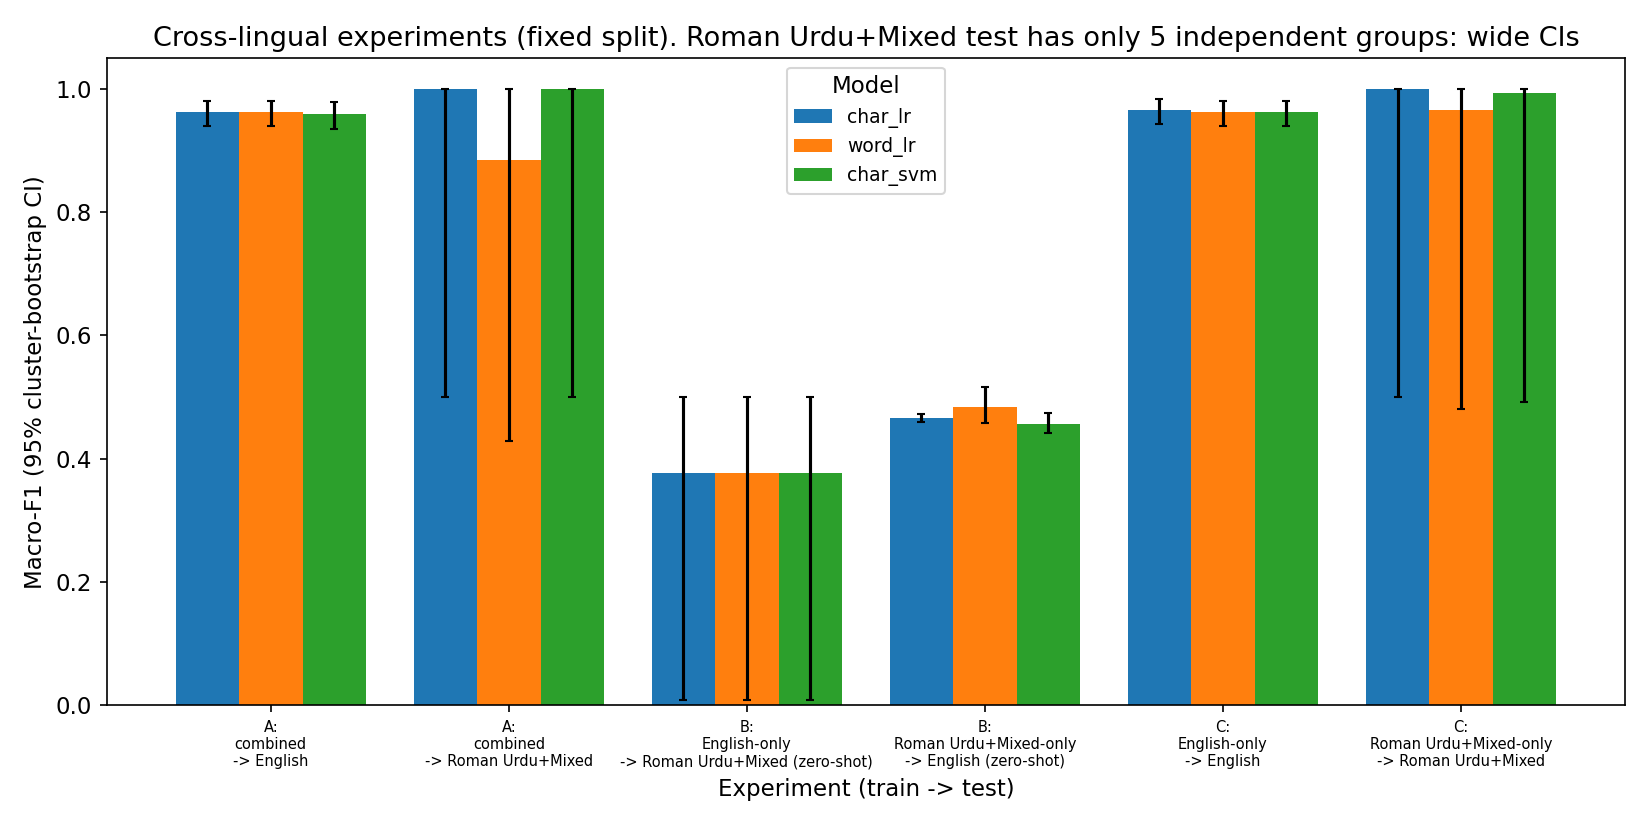

In [3]:
x = pd.read_csv(C.RESULTS_DIR / 'cross_lingual_results.csv')
display(x[['model_id','experiment','n_train','n_test','n_groups','macro_f1','macro_f1_ci_low','macro_f1_ci_high','status']].round(3))
display(Image(str(C.FIGURES_DIR / 'results_cross_lingual.png'), width=800))

## Error analysis and efficiency

(3937, 7)


,language,true_label,predicted_label,confidence,error_category,model
3429,English,Scam,Legitimate,0.6530,FN|english,TFIDF-word + LinearSVM (aug-trained)
2915,Mixed/Code-Switched,Legitimate,Scam,0.6281,FP|code_switched;ambiguous,TFIDF-word + NaiveBayes (aug-trained)
1768,Mixed/Code-Switched,Legitimate,Scam,0.5471,FP|code_switched;ambiguous;perturbed:code_switching,TFIDF-word + LogisticRegression
900,English,Scam,Legitimate,0.6864,FN|english;perturbed:punctuation_variation,TFIDF-char + NaiveBayes (aug-trained)
1109,Mixed/Code-Switched,Legitimate,Scam,0.8757,FP|code_switched;perturbed:roman_urdu_spelling_variation,TFIDF-char + NaiveBayes (aug-trained)
3921,Mixed/Code-Switched,Legitimate,Scam,0.5450,FP|code_switched;ambiguous;perturbed:code_switching,TFIDF-word + LinearSVM (aug-trained)
1271,English,Scam,Legitimate,0.5147,FN|english;ambiguous;perturbed:word_spacing_variation,TFIDF-char + LinearSVM
3290,English,Scam,Legitimate,0.6962,FN|english;perturbed:casing_variation,TFIDF-word + LinearSVM


,model,slice,n,errors,error_rate,FP,FN
28,TFIDF-char + LogisticRegression,originals,935,12,0.013,1,11
29,TFIDF-char + LogisticRegression,perturbed,7948,129,0.016,9,120
30,TFIDF-char + LogisticRegression,originals: English,782,12,0.015,1,11
31,TFIDF-char + LogisticRegression,originals: Roman Urdu + Mixed,149,0,0.000,0,0
32,TFIDF-char + LogisticRegression,originals: short (<30 chars),110,1,0.009,1,0
33,TFIDF-char + LogisticRegression,perturbed:casing_variation,935,12,0.013,1,11
34,TFIDF-char + LogisticRegression,perturbed:character_deletion,935,15,0.016,2,13
35,TFIDF-char + LogisticRegression,perturbed:character_substitution,935,19,0.020,2,17
36,TFIDF-char + LogisticRegression,perturbed:code_switching,700,11,0.016,1,10
37,TFIDF-char + LogisticRegression,perturbed:informal_abbreviation,632,12,0.019,0,12


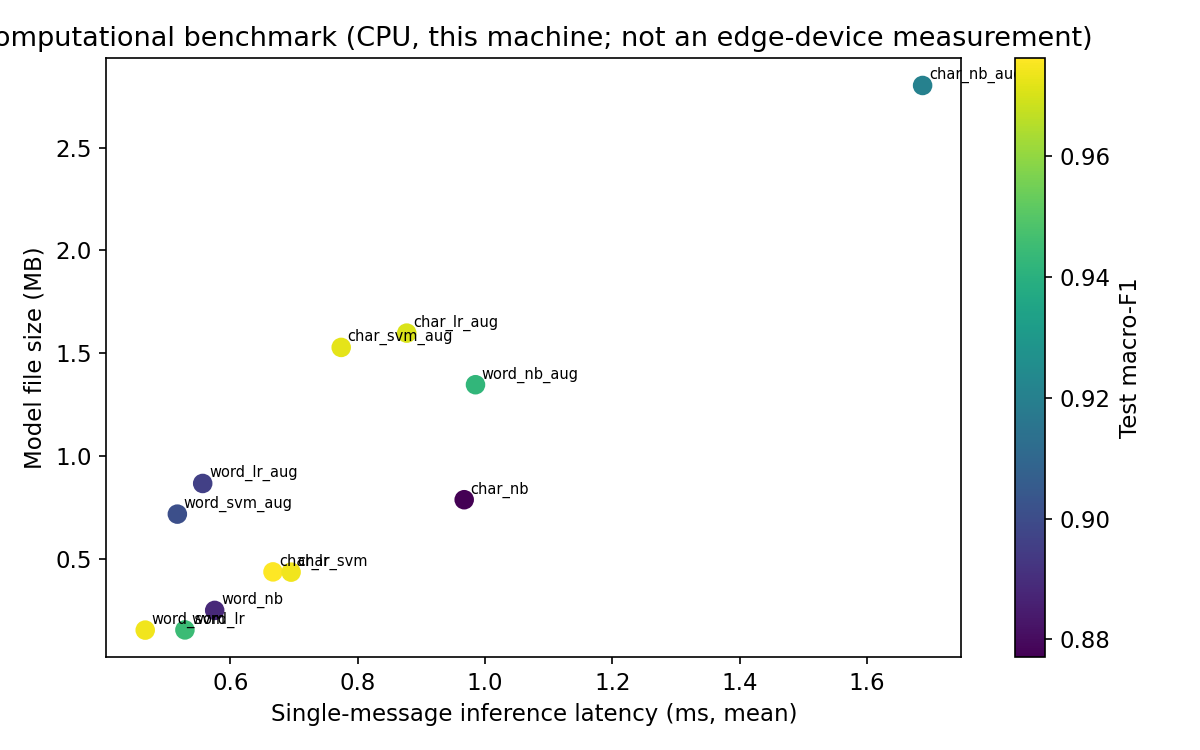

In [4]:
e = pd.read_csv(C.RESULTS_DIR / 'error_analysis.csv')
print(e.shape); display(e.drop(columns=['message']).sample(8, random_state=0))   # message text is not displayed (dataset licensing)
display(pd.read_csv(C.TABLES_DIR / 'error_summary.csv').query("model == 'TFIDF-char + LogisticRegression'").round(3))
display(Image(str(C.FIGURES_DIR / 'results_efficiency.png'), width=600))